STRUCTURE FROM MOTION



In [ ]:
# Install all necessary libraries
!pip install torch torchvision opencv-python matplotlib tqdm ipympl -q
!pip install gtsam

from pathlib import Path

if Path.cwd().name != "LightGlue":
    !git clone --quiet https://github.com/cvg/LightGlue/
    %cd LightGlue
    !pip install --progress-bar off --quiet -e .

fatal: destination path 'LightGlue' already exists and is not an empty directory.
/content/LightGlue
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for lightglue (pyproject.toml) ... done


In [ ]:
# All imports
import torch
import cv2
from pathlib import Path
import numpy as np
from tqdm import tqdm
import itertools
import gtsam
from google.colab import drive
from matplotlib import pyplot as plt
import plotly.graph_objects as go

# LightGlue imports
from lightglue import LightGlue, SuperPoint, DISK, viz2d
from lightglue.utils import load_image, rbd

In [ ]:
# --- Configuration and Global Constants ---

# Mount Google Drive
drive.mount('/content/drive')

# Define Paths
# Update this path to the project folder
BASE_DIR = Path('/content/drive/MyDrive/HW4')
DATA_DIR = BASE_DIR / 'data'
FEATURES_DIR = Path('features') # Local features cache
FEATURES_DIR.mkdir(exist_ok=True) # Create cache dir

# Setup Device
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

# Camera Intrinsics (K-Matrix) from COLMAP
# K = [[f, 0, cx], [0, f, cy], [0, 0, 1]]
K = np.array([
    [1718.5, 0,       540.0],
    [0,       1718.5, 960.0],
    [0,       0,       1.0]
])

# Reconstruction Parameters
MIN_INLIER_THRESHOLD = 20 # Min inliers for a pair to be geometrically verified

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cpu


FEATURE EXTRACTION & MATCHING

In [ ]:
# Load the SuperPoint feature extractor and LightGlue matcher
extractor = SuperPoint(max_num_keypoints=2048).eval().to(DEVICE)
matcher = LightGlue(features='superpoint').eval().to(DEVICE)

# Get a sorted list of all image paths
image_paths = sorted(list(DATA_DIR.glob('*.png')))
num_images = len(image_paths)
print(f"Found {num_images} images in {DATA_DIR}")

Found 24 images in /content/drive/MyDrive/HW4/data


In [ ]:
# --- Extract and Save Features ---

print("--- Extracting features ---")
for i, path in tqdm(enumerate(image_paths), total=num_images):
    feature_path = FEATURES_DIR / f'{path.stem}_feats.pt'

    # Skip if features already exist
    if feature_path.exists():
        continue

    image = load_image(path).to(DEVICE)

    with torch.no_grad():
        feats_raw = extractor.extract(image)
        # Move to CPU first
        feats_on_cpu = {k: v.cpu() for k, v in feats_raw.items()}
        # Remove the batch dimension before saving
        feats_final = rbd(feats_on_cpu)

    # Save the clean, batch-less feature dictionary
    torch.save(feats_final, feature_path)

print("Feature extraction complete.")

--- Extracting features ---


100%|██████████| 24/24 [00:00<00:00, 20585.54it/s]

Feature extraction complete.


In [ ]:
# --- Match Feature Pairs ---

all_matches = {}
temporal_window = 6
pairs_to_match = []

# Generate pairs with a lookahead
for i in range(num_images):
    for j in range(i + 1, min(i + 1 + temporal_window, num_images)):
        pairs_to_match.append((i, j))

# Remove duplicates and sort
pairs_to_match = sorted(list(set(pairs_to_match)))
print(f"Total unique pairs to match: {len(pairs_to_match)}")

# Perform the matching
for i, j in tqdm(pairs_to_match):
    # Load pre-computed features (already on CPU)
    feats0_path = FEATURES_DIR / f'{image_paths[i].stem}_feats.pt'
    feats1_path = FEATURES_DIR / f'{image_paths[j].stem}_feats.pt'
    feats0 = torch.load(feats0_path)
    feats1 = torch.load(feats1_path)

    # Add batch dimension and move to GPU for matcher
    feats0_gpu = {k: v.unsqueeze(0).to(DEVICE) for k, v in feats0.items()}
    feats1_gpu = {k: v.unsqueeze(0).to(DEVICE) for k, v in feats1.items()}

    # Match on the GPU
    with torch.no_grad():
        matches01_raw = matcher({"image0": feats0_gpu, "image1": feats1_gpu})

    # Move tensors to CPU for storage
    matches01_on_cpu = {
        k: (v.cpu() if isinstance(v, torch.Tensor) else v)
        for k, v in matches01_raw.items()
    }
    matches01_final = rbd(matches01_on_cpu)

    # Store the final, cleaned-up results
    all_matches[(i, j)] = {
        'matches': matches01_final['matches'],
        'scores': matches01_final['matching_scores0']
    }

print(f"--- Successfully matched {len(all_matches)} pairs ---")

Total unique pairs to match: 123


100%|██████████| 123/123 [03:34<00:00,  1.75s/it]

--- Successfully matched 123 pairs ---


Even though I am submitting just the pair wise matching of one pair, it can be run using the commented snippet which I used to visually verify all the pairs.

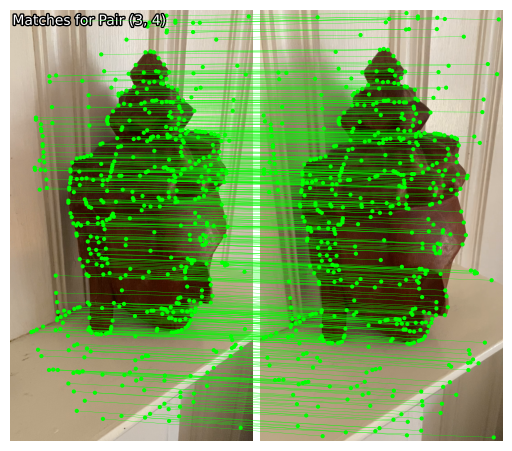

In [ ]:
# --- Visualize an Example Match ---

pair_to_show = (3, 4) # Example: shows matches between image 3 and 4

# for pair_to_show in all_matches.keys():
if pair_to_show in all_matches:
    i, j = pair_to_show
    image0 = load_image(image_paths[i])
    image1 = load_image(image_paths[j])
    feats0 = torch.load(FEATURES_DIR / f'{image_paths[i].stem}_feats.pt')
    feats1 = torch.load(FEATURES_DIR / f'{image_paths[j].stem}_feats.pt')

    matches_data = all_matches[pair_to_show]
    matches = matches_data['matches']

    kpts0, kpts1 = feats0["keypoints"], feats1["keypoints"]
    m_kpts0, m_kpts1 = kpts0[matches[..., 0]], kpts1[matches[..., 1]]

    axes = viz2d.plot_images([image0, image1])
    viz2d.plot_matches(m_kpts0, m_kpts1, color="lime", lw=0.2)
    viz2d.add_text(0, f'Matches for Pair {pair_to_show}', fs=10)
    plt.show()
else:
    print(f"Pair {pair_to_show} not in all_matches. Skipping visualization.")

HELPER FUNCTIONS FOR GEOMETRIC METHODS

In [ ]:
# --- F-Matrix and RANSAC Functions ---

def compute_fundamental_matrix(points1, points2):
    # Computes the Fundamental Matrix F using the 8-point algorithm with normalization

    # Convert to homogeneous coordinates
    p1_h = np.hstack((points1, np.ones((len(points1), 1))))
    p2_h = np.hstack((points2, np.ones((len(points2), 1))))

    # Calculate normalization matrices
    def get_normalization_matrix(points):
        centroid = np.mean(points, axis=0)
        scale = np.sqrt(2) / np.mean(np.linalg.norm(points - centroid, axis=1))
        T = np.array([
            [scale, 0, -scale * centroid[0]],
            [0, scale, -scale * centroid[1]],
            [0, 0, 1]
        ])
        return T

    T1 = get_normalization_matrix(points1)
    T2 = get_normalization_matrix(points2)

    # Apply normalization
    p1_norm = (T1 @ p1_h.T).T
    p2_norm = (T2 @ p2_h.T).T

    # Form the A matrix
    A = np.zeros((len(points1), 9))
    for i in range(len(points1)):
        u1, v1, _ = p1_norm[i]
        u2, v2, _ = p2_norm[i]
        A[i] = [u2 * u1, u2 * v1, u2, v2 * u1, v2 * v1, v2, u1, v1, 1]

    # Solve Af=0 using SVD
    _, _, Vt = np.linalg.svd(A)
    F_norm = Vt[-1].reshape(3, 3)

    # Enforce the rank-2 constraint
    U, S, Vt_f = np.linalg.svd(F_norm)
    S[2] = 0  # Set the smallest singular value to zero
    F_norm_rank2 = U @ np.diag(S) @ Vt_f

    # Denormalize the Fundamental Matrix
    F = T2.T @ F_norm_rank2 @ T1

    # Normalize the final F matrix
    F = F / np.linalg.norm(F)
    return F

def get_inlier_mask(points1, points2, F, threshold):
    # Calculates the Sampson distance and returns a mask of inliers
    p1_h = np.hstack((points1, np.ones((len(points1), 1))))
    p2_h = np.hstack((points2, np.ones((len(points2), 1))))

    l2 = p1_h @ F.T  # Epipolar lines in image 2
    l1 = p2_h @ F     # Epipolar lines in image 1

    numerator = (np.sum(p2_h * l2, axis=1))**2
    denominator = l2[:, 0]**2 + l2[:, 1]**2 + l1[:, 0]**2 + l1[:, 1]**2 + 1e-8

    sampson_dist_sq = numerator / denominator
    mask = sampson_dist_sq < threshold**2
    return mask

def find_fundamental_matrix_ransac(points1, points2, threshold=1.3, confidence=0.87):
    # Performs RANSAC to find the best Fundamental Matrix F
    best_F = None
    best_mask = None
    max_inliers = 0
    num_points = len(points1)
    n_sample_size = 8

    num_iterations = float('inf')
    current_iteration = 0

    while current_iteration < num_iterations:
        indices = np.random.choice(num_points, n_sample_size, replace=False)
        sample1, sample2 = points1[indices], points2[indices]

        try:
            F_candidate = compute_fundamental_matrix(sample1, sample2)
            if F_candidate is None: continue
        except np.linalg.LinAlgError:
            current_iteration += 1
            continue

        mask_candidate = get_inlier_mask(points1, points2, F_candidate, threshold)
        num_inliers = np.sum(mask_candidate)

        if num_inliers > max_inliers:
            max_inliers = num_inliers
            best_F = F_candidate
            best_mask = mask_candidate

            inlier_ratio = num_inliers / num_points
            if inlier_ratio > 1e-6:
                N = np.log(1 - confidence) / np.log(1 - inlier_ratio**n_sample_size + 1e-9)
                num_iterations = min(num_iterations, N)

        current_iteration += 1
        if current_iteration > 2000:
             break

    # Refit the model using all found inliers
    if max_inliers > n_sample_size:
        inlier_pts1 = points1[best_mask]
        inlier_pts2 = points2[best_mask]
        best_F = compute_fundamental_matrix(inlier_pts1, inlier_pts2)
        best_mask = get_inlier_mask(points1, points2, best_F, threshold)

    if best_mask is not None:
        best_mask = best_mask.flatten()

    return best_F, best_mask

In [ ]:
# --- E-Matrix and Pose Decomposition Functions ---

def enforce_essential_unit_sigma(E):
    # Projects a 3x3 matrix E onto the essential-manifold with singular values (1,1,0)
    U, S, Vt = np.linalg.svd(E)
    if np.linalg.det(U @ Vt) < 0:
        Vt = -Vt
    E_proj = U @ np.diag([1.0, 1.0, 0.0]) @ Vt
    return E_proj

def decompose_essential(E):
    # Decomposes the essential matrix E into four pose hypotheses (R, t)
    U, S, Vt = np.linalg.svd(E)
    if np.linalg.det(U @ Vt) < 0:
        Vt = -Vt

    W = np.array([[0, -1,  0], [1,  0,  0], [0,  0,  1]], dtype=float)

    R1 = U @ W  @ Vt
    R2 = U @ W.T @ Vt

    if np.linalg.det(R1) < 0: R1 = -R1
    if np.linalg.det(R2) < 0: R2 = -R2

    t = U[:, 2]
    poses = [
        {'R': R1, 't':  t}, {'R': R1, 't': -t},
        {'R': R2, 't':  t}, {'R': R2, 't': -t},
    ]
    return poses

In [ ]:
# --- Triangulation and Cheirality Functions ---

def _build_P(K, R, t):
    # Builds the 3x4 projection matrix P = K [R|t]
    Rt = np.hstack([R, t.reshape(3, 1)])
    return K @ Rt

def _triangulate_point_linear(P0, P1, x0, x1):
    # Linear DLT triangulation for a single correspondence
    x0h = np.array([x0[0], x0[1], 1.0], dtype=float)
    x1h = np.array([x1[0], x1[1], 1.0], dtype=float)

    A = np.vstack([
        x0h[0] * P0[2] - P0[0],
        x0h[1] * P0[2] - P0[1],
        x1h[0] * P1[2] - P1[0],
        x1h[1] * P1[2] - P1[1],
    ])
    _, _, Vt = np.linalg.svd(A)
    Xh = Vt[-1]
    X = Xh[:3] / (Xh[3] + 1e-8)
    return X

def _reproject(P, X):
    # Projects 3D point X (3,) with P (3x4) to pixel coords
    Xh = np.hstack([X, 1.0])
    x = P @ Xh
    return x[:2] / (x[2] + 1e-8)

def cheirality_for_pose(K, R, t, pts0, pts1, depth_eps=1e-6):
    # Evaluates one pose (R,t) by triangulating all points and checking for positive depth and reprojection error

    P0 = _build_P(K, np.eye(3), np.zeros(3))
    P1 = _build_P(K, R, t)

    z0_list, z1_list = [], []
    err0_list, err1_list = [], []
    pos_mask = []

    for p0, p1 in zip(pts0, pts1):
        X = _triangulate_point_linear(P0, P1, p0, p1)
        if np.any(np.isnan(X)):
            z0_list.append(-1); z1_list.append(-1)
            err0_list.append(np.inf); err1_list.append(np.inf)
            pos_mask.append(False)
            continue

        # Depth in cam0
        z0 = X[2]

        # Depth in cam1
        Xc1 = R @ X + t.reshape(3)
        z1 = Xc1[2]

        # Reprojection errors
        x0_hat = _reproject(P0, X)
        x1_hat = _reproject(P1, X)

        if np.any(np.isnan(x0_hat)) or np.any(np.isnan(x1_hat)):
             err0 = np.inf; err1 = np.inf
        else:
            err0 = np.linalg.norm(x0_hat - p0)
            err1 = np.linalg.norm(x1_hat - p1)

        z0_list.append(z0)
        z1_list.append(z1)
        err0_list.append(err0)
        err1_list.append(err1)
        pos_mask.append((z0 > depth_eps) and (z1 > depth_eps))

    z0 = np.array(z0_list)
    z1 = np.array(z1_list)
    reproj_err0 = np.array(err0_list)
    reproj_err1 = np.array(err1_list)
    positives = np.array(pos_mask, dtype=bool)

    return positives, z0, z1, reproj_err0, reproj_err1

def select_pose_by_cheirality(K, pose_candidates, pts0, pts1, depth_eps=1e-6):
    # Tests all four (R,t) candidates and picks the one with the most positive depths
    best_idx, best_pose, best_count = None, None, -1
    metrics = {}

    for i, pose in enumerate(pose_candidates):
        R, t = pose['R'], pose['t']
        positives, z0, z1, e0, e1 = cheirality_for_pose(K, R, t, pts0, pts1, depth_eps)

        count = int(positives.sum())
        # Calculate mean error for inlier points
        mean_err = float(np.mean((e0[positives] + e1[positives]) * 0.5)) if count > 0 else np.inf

        metrics[i] = {
            'count_positive': count,
            'mean_reproj_err': mean_err,
            'z0_pos_ratio': float((z0 > depth_eps).mean()),
            'z1_pos_ratio': float((z1 > depth_eps).mean()),
        }

        # Select best pose based on inlier count, then reprojection error
        current_best_err = metrics.get(best_idx, {}).get('mean_reproj_err', np.inf)
        if count > best_count or (count == best_count and mean_err < current_best_err):
            best_idx, best_pose, best_count = i, pose, count

    # Handle case where no pose is valid
    if best_idx is None:
         return None, None, {'count_positive': 0, 'mean_reproj_err': np.inf, 'z0_pos_ratio': 0.0, 'z1_pos_ratio': 0.0}

    return best_idx, best_pose, metrics[best_idx]

In [ ]:
# --- Data Helper Functions ---

def load_all_keypoints(image_paths, features_dir):
    # Loads all keypoints and image sizes from disk into a dictionary
    print("--- Loading all keypoints into memory ---")
    all_keypoints = {}
    all_image_sizes = {} # Also storing image size for the visualizer
    for i, path in enumerate(tqdm(image_paths)):
        feats = torch.load(features_dir / f'{path.stem}_feats.pt')
        all_keypoints[i] = _safe_to_numpy(feats['keypoints'])
        all_image_sizes[i] = _safe_to_numpy(feats['image_size'])
    return all_keypoints, all_image_sizes

def _safe_to_numpy(x):
    # Converts torch.Tensor to numpy, otherwise returns np.asarray
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)

def _extract_inlier_points_for_pair(pair, geometric_verification, features_dir, image_paths):
    # Extracts the (N,2) numpy arrays of inlier pixel coords for a given pair
    i, j = pair
    # Load keypoints
    feats0 = torch.load(features_dir / f'{image_paths[i].stem}_feats.pt')
    feats1 = torch.load(features_dir / f'{image_paths[j].stem}_feats.pt')
    kpts0 = _safe_to_numpy(feats0['keypoints'])
    kpts1 = _safe_to_numpy(feats1['keypoints'])

    # Load matches and inliers
    data = geometric_verification[pair]
    matches = _safe_to_numpy(data['matches'])
    inliers = data['inliers'].astype(bool)

    # Index into keypoints with inlier correspondences
    idx0 = matches[inliers, 0].astype(int)
    idx1 = matches[inliers, 1].astype(int)
    pts0 = kpts0[idx0]  # Nx2
    pts1 = kpts1[idx1]  # Nx2
    return pts0, pts1

GEOMETRIC VERIFICATION

In [ ]:
# --- Run Geometric Verification ---

geometric_verification = {}
print("--- Running geometric verification (RANSAC) ---")

for pair, data in tqdm(all_matches.items()):
    i, j = pair

    feats0 = torch.load(FEATURES_DIR / f'{image_paths[i].stem}_feats.pt')
    feats1 = torch.load(FEATURES_DIR / f'{image_paths[j].stem}_feats.pt')
    kpts0, kpts1 = feats0['keypoints'], feats1['keypoints']
    matches = data['matches']

    mkpts0 = kpts0[matches[..., 0]].numpy()
    mkpts1 = kpts1[matches[..., 1]].numpy()

    if len(mkpts0) < 8:
        continue

    F, inlier_mask = find_fundamental_matrix_ransac(mkpts0, mkpts1)
    if F is None:
        continue

    num_inliers = np.sum(inlier_mask)

    # Filter out pairs with insufficient geometric support
    if num_inliers < MIN_INLIER_THRESHOLD:
        continue

    # Store results only for verified pairs
    geometric_verification[pair] = {
        'F': F,
        'inliers': inlier_mask.astype(bool).flatten(),
        'num_inliers': num_inliers,
        'matches': matches # Keep the original matches
    }

print(f"\nGeometric verification complete.")
print(f"Total pairs verified (>{MIN_INLIER_THRESHOLD} inliers): {len(geometric_verification)}")

--- Running geometric verification (RANSAC) ---


100%|██████████| 123/123 [00:53<00:00,  2.29it/s]


Geometric verification complete.
Total pairs verified (>20 inliers): 118


In [ ]:
# --- Calculate Essential Matrices ---

print("--- Calculating Essential Matrices ---")
for pair, data in geometric_verification.items():
    F = data['F']
    E_raw = K.T @ F @ K
    E = enforce_essential_unit_sigma(E_raw)
    data['E'] = E  # Add the new E matrix to the dictionary

print("Essential matrices calculated and added.")

--- Calculating Essential Matrices ---
Essential matrices calculated and added.


In [ ]:
# --- Run Cheirality Check ---

def run_cheirality_on_all_pairs(geometric_verification, features_dir, image_paths, K):
    # Runs the cheirality check on all verified pairs to find the best pose
    results = []
    print("--- Running cheirality check on all pairs ---")
    for pair, data in tqdm(geometric_verification.items()):
        pts0, pts1 = _extract_inlier_points_for_pair(pair, geometric_verification, features_dir, image_paths)
        if pts0.shape[0] < 8:
            continue

        E = data['E']
        pose_candidates = decompose_essential(E)

        best_idx, best_pose, metrics = select_pose_by_cheirality(
            K, pose_candidates, pts0, pts1
        )

        # Persist detailed results back into the dict
        data['pose_candidates'] = pose_candidates
        data['best_pose_idx'] = best_idx
        data['best_pose'] = best_pose
        data['cheirality'] = metrics

        # Summary row for ranking/printing
        res = {
            'pair': pair,
            'num_inliers': int(data['num_inliers']),
            'best_idx': best_idx,
            **metrics
        }
        results.append(res)

    # Sort by positive-depth count-descending, then mean reprojection error-ascending
    results.sort(key=lambda r: (-r['count_positive'], r['mean_reproj_err']))
    return results

def print_cheirality_summary(results, top_k=10):
   # Prints a summary of the best pairs
   print(f'\nCheirality summary (top {top_k}):')
   for r in results[:top_k]:
       print(f'Pair {r["pair"]}: positives={r["count_positive"]}, '
             f'inliers={r["num_inliers"]}, '
             f'mean_err={r["mean_reproj_err"]:.3f}px, '
             f'best_pose_idx={r["best_idx"]}')

# Run the check
cheirality_results = run_cheirality_on_all_pairs(geometric_verification, FEATURES_DIR, image_paths, K)
print_cheirality_summary(cheirality_results, top_k=15)

--- Running cheirality check on all pairs ---


100%|██████████| 118/118 [00:11<00:00, 10.24it/s]


Cheirality summary (top 15):
Pair (2, 3): positives=405, inliers=407, mean_err=0.952px, best_pose_idx=3
Pair (1, 3): positives=380, inliers=380, mean_err=2.240px, best_pose_idx=1
Pair (0, 2): positives=363, inliers=363, mean_err=0.684px, best_pose_idx=3
Pair (1, 2): positives=361, inliers=389, mean_err=0.695px, best_pose_idx=1
Pair (0, 3): positives=349, inliers=349, mean_err=0.501px, best_pose_idx=1
Pair (16, 17): positives=328, inliers=328, mean_err=2.572px, best_pose_idx=0
Pair (5, 6): positives=324, inliers=324, mean_err=1.875px, best_pose_idx=0
Pair (21, 22): positives=320, inliers=320, mean_err=3.009px, best_pose_idx=3
Pair (19, 20): positives=307, inliers=307, mean_err=1.388px, best_pose_idx=2
Pair (10, 11): positives=301, inliers=301, mean_err=1.010px, best_pose_idx=3
Pair (0, 1): positives=294, inliers=559, mean_err=0.421px, best_pose_idx=1
Pair (11, 12): positives=284, inliers=284, mean_err=1.616px, best_pose_idx=3
Pair (20, 21): positives=284, inliers=314, mean_err=5.548px,

In [ ]:
# --- Select the Seed Pair ---

if not cheirality_results:
    raise RuntimeError("No valid pairs")

best_seed = cheirality_results[0]
seed_pair = best_seed['pair']
seed_pose_info = geometric_verification[seed_pair]['best_pose']

print(f"\n--- Selected Seed Pair: {seed_pair} ---")
print(f"Positive Points: {best_seed['count_positive']}")
print(f"Mean Reproj Err: {best_seed['mean_reproj_err']:.3f}px")


--- Selected Seed Pair: (2, 3) ---
Positive Points: 405
Mean Reproj Err: 0.952px


INCREMENTAL IMAGE REGISTRATION PIPELINE

In [ ]:
# --- PnP Registration Function ---

def register_new_image_pnp(img_new_idx, poses_world, points_3d_world, point_id_to_kpt_idx, geometric_verification, image_paths, features_dir, K):
    # Registers a new image to the existing 3D map using RANSAC-PnP
    print(f"--- Registering Image {img_new_idx} via PnP ---")

    # Find 2D-3D correspondences
    registered_img_indices = poses_world.keys()
    feats_new = torch.load(features_dir / f'{image_paths[img_new_idx].stem}_feats.pt')
    kpts_new = feats_new['keypoints'].cpu().numpy()

    # Invert observation maps for fast lookup: {img_idx: {kpt_idx: point_id}}
    kpt_idx_to_point_id_maps = {}
    for idx in registered_img_indices:
        if poses_world[idx] is None or idx not in point_id_to_kpt_idx:
            continue
        kpt_idx_to_point_id_maps[idx] = {v: k for k, v in point_id_to_kpt_idx[idx].items()}

    points_3d_for_pnp = [] # List of 3D np.array
    points_2d_for_pnP = [] # List of 2D (u,v) coords
    pnp_matches_to_ids = []# To map PnP inliers back to point IDs
    seen_point_ids = set()

    for img_map_idx in registered_img_indices:
        if poses_world[img_map_idx] is None:
            continue

        pair_to_check = tuple(sorted((img_map_idx, img_new_idx)))
        if pair_to_check not in geometric_verification:
            continue

        # Check if we have a valid lookup map for this index
        if img_map_idx not in kpt_idx_to_point_id_maps:
            continue

        data = geometric_verification[pair_to_check]
        matches = data['matches'].cpu().numpy()
        inliers = data['inliers'].astype(bool)
        inlier_matches = matches[inliers]

        kpt_idx_to_point_id = kpt_idx_to_point_id_maps[img_map_idx]
        swap = (pair_to_check[0] == img_new_idx)

        for match in inlier_matches:
            kpt_idx_new = match[0] if swap else match[1]
            kpt_idx_map = match[1] if swap else match[0]

            if kpt_idx_map in kpt_idx_to_point_id:
                point_id = kpt_idx_to_point_id[kpt_idx_map]
                if point_id in seen_point_ids:
                    continue

                points_3d_for_pnp.append(points_3d_world[point_id])
                points_2d_for_pnP.append(kpts_new[kpt_idx_new])
                pnp_matches_to_ids.append( (point_id, kpt_idx_new) )
                seen_point_ids.add(point_id)

    print(f"Found {len(points_3d_for_pnp)} unique 2D-3D correspondences for PnP.")

    # Solve for the new pose using PnP
    MIN_PNP_POINTS = 8
    if len(points_3d_for_pnp) < MIN_PNP_POINTS:
        print(f"Not enough points for PnP ({len(points_3d_for_pnp)} < {MIN_PNP_POINTS}), skipping image {img_new_idx}.")
        return False

    obj_points = np.array(points_3d_for_pnp, dtype=np.float32)
    img_points = np.array(points_2d_for_pnP, dtype=np.float32)

    try:
        success, rvec, tvec, inliers_pnp = cv2.solvePnPRansac(
            obj_points, img_points, K, distCoeffs=None,
            iterationsCount=1000, reprojectionError=3.0,
            confidence=0.9, flags=cv2.SOLVEPNP_ITERATIVE
        )
    except cv2.error as e:
        print(f"PnP solve failed with error: {e}")
        success = False

    if not success:
        print(f"PnP RANSAC failed for image {img_new_idx}.")
        return False

    # Add the new pose to our map
    R_world_new, _ = cv2.Rodrigues(rvec)
    pose_world_new = gtsam.Pose3(gtsam.Rot3(R_world_new), gtsam.Point3(tvec.flatten()))
    poses_world[img_new_idx] = pose_world_new
    point_id_to_kpt_idx[img_new_idx] = {} # Initialize observation list

    # Record the 2D-3D observations that agree with the PnP solution
    if inliers_pnp is not None:
        for i in inliers_pnp.flatten():
            point_id, kpt_idx_new = pnp_matches_to_ids[i]
            point_id_to_kpt_idx[img_new_idx][point_id] = kpt_idx_new
        print(f"Recorded {len(inliers_pnp)} inlier observations for new pose.")

    return True

In [ ]:
def get_triangulation_angle(pose0, pose1, X_world):
    # Calculates the angle (in degrees) between two camera rays for a 3D point

    # Get camera centers
    cam0_center = pose0.translation()
    cam1_center = pose1.translation()

    # Create vectors from camera centers to the 3D point
    v0 = X_world - cam0_center
    v1 = X_world - cam1_center

    # Normalize vectors
    v0_norm = v0 / np.linalg.norm(v0)
    v1_norm = v1 / np.linalg.norm(v1)

    # Calculate the angle between the vectors
    dot_product = np.clip(np.dot(v0_norm, v1_norm), -1.0, 1.0)
    angle_rad = np.arccos(dot_product)

    return np.degrees(angle_rad)

In [ ]:
# --- Point Triangulation Function ---

def triangulate_new_points(img_new_idx, poses_world, points_3d_world, point_id_to_kpt_idx, geometric_verification, image_paths, features_dir, K):
    # Triangulates new 3D points by linking the new image to all existing map images
    global point_id_counter # Use the global point ID counter

    # Minimum angle for a stable triangulation
    MIN_TRIANGULATION_ANGLE = 1.5  # in degrees

    print(f"--- Triangulating new points for image {img_new_idx} ---")
    total_newly_triangulated_points = 0
    pose_new = poses_world[img_new_idx]
    P_new = _build_P(K, pose_new.rotation().matrix(), pose_new.translation())

    # Invert observation maps for fast lookup: {img_idx: {kpt_idx: point_id}}
    kpt_to_3d_point_maps = {}
    for idx in poses_world.keys():
        if idx in point_id_to_kpt_idx:
            kpt_to_3d_point_maps[idx] = {v: k for k, v in point_id_to_kpt_idx[idx].items()}
        else:
            kpt_to_3d_point_maps[idx] = {}

    for img_map_idx in poses_world.keys():
        if img_map_idx == img_new_idx or poses_world[img_map_idx] is None:
            continue

        pair_to_check = tuple(sorted((img_map_idx, img_new_idx)))
        if pair_to_check not in geometric_verification:
            continue

        data = geometric_verification[pair_to_check]
        inliers = data['inliers'].astype(bool)
        inlier_matches = data['matches'].cpu().numpy()[inliers]

        pts0, pts1 = _extract_inlier_points_for_pair(pair_to_check, geometric_verification, features_dir, image_paths)
        pose_map = poses_world[img_map_idx]
        P_map = _build_P(K, pose_map.rotation().matrix(), pose_map.translation())

        swap = (pair_to_check[0] == img_new_idx)
        pts_new = pts0 if swap else pts1
        pts_map = pts1 if swap else pts0

        for k in range(len(inlier_matches)):
            kpt_idx_new = inlier_matches[k, 0] if swap else inlier_matches[k, 1]
            kpt_idx_map = inlier_matches[k, 1] if swap else inlier_matches[k, 0]

            # Check if either keypoint already observes a 3D point
            if kpt_idx_new in kpt_to_3d_point_maps[img_new_idx] or \
               kpt_idx_map in kpt_to_3d_point_maps[img_map_idx]:
                continue

            X_world = _triangulate_point_linear(P_new, P_map, pts_new[k], pts_map[k])

            # Cheirality check
            X_cam_new = pose_new.transformTo(X_world)
            X_cam_map = pose_map.transformTo(X_world)
            if X_cam_new[2] < 0 or X_cam_map[2] < 0:
                continue

            # Check if the angle between the two camera rays is large enough
            angle = get_triangulation_angle(pose_new, pose_map, X_world)
            if angle < MIN_TRIANGULATION_ANGLE:
                continue

            # Add this new point to the world
            current_point_id = point_id_counter
            points_3d_world[current_point_id] = X_world
            point_id_to_kpt_idx[img_new_idx][current_point_id] = kpt_idx_new
            point_id_to_kpt_idx[img_map_idx][current_point_id] = kpt_idx_map
            point_id_counter += 1
            total_newly_triangulated_points += 1

    print(f"Triangulated {total_newly_triangulated_points} new 3D points.")

In [ ]:
# --- Next Best View Function ---

def find_next_best_view(poses_world, point_id_to_kpt_idx, geometric_verification, image_paths):
    # Finds the best unregistered image to add to the map
    registered_ids = set(poses_world.keys())

    # Invert map for fast lookup
    kpt_to_3d_point_maps = {}
    for img_idx in registered_ids:
        if img_idx in point_id_to_kpt_idx:
            kpt_to_3d_point_maps[img_idx] = {v: k for k, v in point_id_to_kpt_idx[img_idx].items()}

    candidate_scores = {}

    for img_idx_candidate in range(len(image_paths)):
        if img_idx_candidate in registered_ids:
            continue

        num_2d3d_matches = 0
        for img_idx_map in registered_ids:
            if img_idx_map not in kpt_to_3d_point_maps: continue

            pair = tuple(sorted((img_idx_candidate, img_idx_map)))
            if pair not in geometric_verification:
                continue

            data = geometric_verification[pair]
            matches = data['matches'].cpu().numpy()
            inliers = data['inliers'].astype(bool)
            inlier_matches = matches[inliers]

            map_kpt_lookup = kpt_to_3d_point_maps[img_idx_map]
            swap = (pair[0] == img_idx_candidate)

            for match in inlier_matches:
                kpt_idx_map = match[1] if not swap else match[0]
                if kpt_idx_map in map_kpt_lookup:
                    num_2d3d_matches += 1

        if num_2d3d_matches > 0:
            candidate_scores[img_idx_candidate] = num_2d3d_matches

    if not candidate_scores:
        return -1 # No more images can be registered

    best_img_idx = sorted(candidate_scores.items(), key=lambda item: -item[1])[0][0]
    print(f"\nNext best view: Image {best_img_idx} with {candidate_scores[best_img_idx]} 2D-3D matches.")
    return best_img_idx

In [ ]:
# --- Global Error Calculation ---

def calculate_total_reprojection_error(poses_world, points_3d_world, point_id_to_kpt_idx, image_paths, features_dir, K):
    """Calculates the mean reprojection error across all observations in the map."""
    all_errors = []
    all_feats = {}

    for img_idx, pose in poses_world.items():
        if pose is None: continue
        if img_idx not in point_id_to_kpt_idx: continue

        # Load features only if needed
        if img_idx not in all_feats:
            feats = torch.load(features_dir / f'{image_paths[img_idx].stem}_feats.pt')
            all_feats[img_idx] = feats['keypoints'].cpu().numpy()

        P = _build_P(K, pose.rotation().matrix(), pose.translation())
        observations = point_id_to_kpt_idx[img_idx]

        for point_id, kpt_idx in observations.items():
            if point_id not in points_3d_world:
                continue

            X_world = points_3d_world[point_id]
            uv_measured = all_feats[img_idx][kpt_idx]
            uv_projected = _reproject(P, X_world)

            if np.any(np.isnan(uv_projected)): continue

            error = np.linalg.norm(uv_measured - uv_projected)
            all_errors.append(error)

    if not all_errors:
        return 0.0
    return np.mean(all_errors)

In [ ]:
# --- Seed the Map ---

# Global Map State
poses_world = {}
points_3d_world = {}
point_id_to_kpt_idx = {}
point_id_counter = 0

i, j = seed_pair
print(f"--- Initializing Map with Seed Pair {seed_pair} ---")

# Get relative pose and inlier keypoints
data = geometric_verification[seed_pair]
R_j_i = data['best_pose']['R']
t_j_i = data['best_pose']['t']
pts0, pts1 = _extract_inlier_points_for_pair(seed_pair, geometric_verification, FEATURES_DIR, image_paths)

# Create the first two poses in the world frame
pose_world_i = gtsam.Pose3(gtsam.Rot3.Identity(), gtsam.Point3(0, 0, 0))
pose_world_j = gtsam.Pose3(gtsam.Rot3(R_j_i), gtsam.Point3(t_j_i))

# Add them to our map
poses_world[i] = pose_world_i
poses_world[j] = pose_world_j
point_id_to_kpt_idx[i] = {}
point_id_to_kpt_idx[j] = {}

# Triangulate the 3D points in the world frame
P0 = _build_P(K, pose_world_i.rotation().matrix(), pose_world_i.translation())
P1 = _build_P(K, pose_world_j.rotation().matrix(), pose_world_j.translation())

matches = data['matches'].cpu().numpy()
inliers = data['inliers'].astype(bool)
inlier_matches = matches[inliers]

newly_triangulated_points = 0
for k in range(len(pts0)):
    X_world = _triangulate_point_linear(P0, P1, pts0[k], pts1[k])

    # Cheirality check
    X_cam0 = pose_world_i.transformTo(X_world)
    X_cam1 = pose_world_j.transformTo(X_world)
    if X_cam0[2] < 0 or X_cam1[2] < 0:
        continue

    # Add the new 3D point to our map
    current_point_id = point_id_counter
    points_3d_world[current_point_id] = X_world

    # Record which 2D keypoints observe this 3D point
    kpt_idx_0 = inlier_matches[k, 0]
    kpt_idx_1 = inlier_matches[k, 1]
    point_id_to_kpt_idx[i][current_point_id] = kpt_idx_0
    point_id_to_kpt_idx[j][current_point_id] = kpt_idx_1

    point_id_counter += 1
    newly_triangulated_points += 1

print(f"Map seeded. Known poses: {len(poses_world)}, 3D points: {len(points_3d_world)}")

--- Initializing Map with Seed Pair (2, 3) ---
Map seeded. Known poses: 2, 3D points: 405


METHODS FOR FILTERING

In [ ]:
# --- Outlier Filtering Function ---

def filter_map_outliers(poses_to_check_idx, points_to_check_ids,
                          poses_world, points_3d_world, point_id_to_kpt_idx,
                          all_feats_local, K, error_threshold=2.0):

    # Filters high-error observations and associated points from the global map

    print(f"--- Filtering outliers from {len(poses_to_check_idx)} poses and {len(points_to_check_ids)} points ---")

    observations_removed = 0
    points_removed = 0

    # Identify all observations with high reprojection error
    observations_to_remove = []
    points_potentially_affected = set()

    for img_idx in poses_to_check_idx:
        # Ensure pose and observations exist and features were loaded
        if img_idx not in poses_world or poses_world.get(img_idx) is None or \
           img_idx not in point_id_to_kpt_idx or img_idx not in all_feats_local:
            continue

        pose = poses_world[img_idx]
        P = _build_P(K, pose.rotation().matrix(), pose.translation())

        observations = list(point_id_to_kpt_idx[img_idx].items())

        for point_id, kpt_idx in observations:
            # Only check points that were part of the last BA
            if point_id not in points_to_check_ids or point_id not in points_3d_world:
                continue

            X_world = points_3d_world[point_id]
            uv_measured = all_feats_local[img_idx][kpt_idx]
            uv_projected = _reproject(P, X_world)

            if np.any(np.isnan(uv_projected)):
                error = np.inf # Treat failed reprojection as an outlier
            else:
                error = np.linalg.norm(uv_measured - uv_projected)

            if error > error_threshold:
                observations_to_remove.append((img_idx, point_id))
                points_potentially_affected.add(point_id)

    # Remove the bad observations from the map
    for img_idx, point_id in observations_to_remove:
        if img_idx in point_id_to_kpt_idx and point_id in point_id_to_kpt_idx[img_idx]:
            del point_id_to_kpt_idx[img_idx][point_id]
            observations_removed += 1

    # Clean up 3D points that now have zero observations
    points_to_delete = set()
    for point_id in points_potentially_affected:
        if point_id not in points_3d_world:
            continue

        is_observed = False
        # Check if any camera still observes this point
        for obs_map in point_id_to_kpt_idx.values():
            if point_id in obs_map:
                is_observed = True
                break

        if not is_observed:
            points_to_delete.add(point_id)

    for point_id in points_to_delete:
        if point_id in points_3d_world:
            del points_3d_world[point_id]
            points_removed += 1

    print(f"Filtering complete. Removed {observations_removed} observations and {points_removed} orphaned 3D points.")

In [ ]:
def filter_far_points_by_distance(poses_world, points_3d_world, point_id_to_kpt_idx, percentile_threshold=98.0):

    print("\n--- Filtering far distance outliers ---")

    # Get all 3D points and their IDs
    point_ids = list(points_3d_world.keys())
    points = np.array(list(points_3d_world.values()))

    if len(points) < 20: # Not enough points to filter
        print("Not enough points to perform distance filtering. Skipping.")
        return points_3d_world, point_id_to_kpt_idx

    # Calculate the centroid (geometric center) of the cloud
    centroid = np.mean(points, axis=0)

    # Calculate the distance of each point from the centroid
    distances = np.linalg.norm(points - centroid, axis=1)

    # Find the distance threshold based on the percentile
    distance_limit = np.percentile(distances, percentile_threshold)
    print(f"Cloud centroid: {centroid.round(2)}")
    print(f"Distance threshold ({percentile_threshold}th percentile): {distance_limit:.2f} units")

    # Find points to remove
    points_to_remove = []
    for i, dist in enumerate(distances):
        if dist > distance_limit:
            points_to_remove.append(point_ids[i])

    print(f"Removing {len(points_to_remove)} outlier points.")

    # Remove the points from the map
    num_removed = 0
    for point_id in points_to_remove:
        if point_id in points_3d_world:
            del points_3d_world[point_id]
            num_removed += 1

        # Also remove their observations from all cameras
        for img_idx in point_id_to_kpt_idx:
            if point_id in point_id_to_kpt_idx[img_idx]:
                del point_id_to_kpt_idx[img_idx][point_id]

    print(f"Removed {num_removed} outlier 3D points from map.")
    return points_3d_world, point_id_to_kpt_idx

RECONSTRUCTION LOOP

In [ ]:
# --- The Main Incremental Reconstruction Loop ---

print("\n" + "="*50)
print("--- STARTING INCREMENTAL RECONSTRUCTION ---")
print("="*50 + "\n")

while True:
    # Find the next best view to add
    next_img_idx = find_next_best_view(
        poses_world, point_id_to_kpt_idx,
        geometric_verification, image_paths
    )

    if next_img_idx == -1:
        print("\n--- No more images to register. Reconstruction complete. ---")
        break

    print(f"\n--- Processing Image {next_img_idx} ---")

    # Register the new image (PnP)
    success = register_new_image_pnp(
        next_img_idx, poses_world, points_3d_world, point_id_to_kpt_idx,
        geometric_verification, image_paths, FEATURES_DIR, K
    )

    if not success:
        print(f"Failed to register image {next_img_idx}. Skipping it.")
        poses_world[next_img_idx] = None # Blacklist this image
        continue

    # Triangulate new points
    triangulate_new_points(
        next_img_idx, poses_world, points_3d_world, point_id_to_kpt_idx,
        geometric_verification, image_paths, FEATURES_DIR, K
    )

    valid_poses = sum(1 for p in poses_world.values() if p is not None)
    print(f"--- Finished processing image {next_img_idx} ---")
    print(f"Current Map Status: {valid_poses} poses, {len(points_3d_world)} points")

final_error = calculate_total_reprojection_error(
    poses_world, points_3d_world, point_id_to_kpt_idx, image_paths, FEATURES_DIR, K
)
print("\n" + "="*50)
print("--- FINAL RECONSTRUCTION ---")
valid_poses = sum(1 for p in poses_world.values() if p is not None)
print(f"Total poses registered: {valid_poses} / {num_images}")
print(f"Total 3D points: {len(points_3d_world)}")
print(f"Final Mean Reprojection Error: {final_error:.4f} pixels")
print("="*50)



--- STARTING INCREMENTAL RECONSTRUCTION ---


Next best view: Image 0 with 264 2D-3D matches.

--- Processing Image 0 ---
--- Registering Image 0 via PnP ---
Found 256 unique 2D-3D correspondences for PnP.
Recorded 154 inlier observations for new pose.
--- Triangulating new points for image 0 ---
Triangulated 4 new 3D points.
--- Finished processing image 0 ---
Current Map Status: 3 poses, 409 points

Next best view: Image 1 with 347 2D-3D matches.

--- Processing Image 1 ---
--- Registering Image 1 via PnP ---
Found 278 unique 2D-3D correspondences for PnP.
Recorded 184 inlier observations for new pose.
--- Triangulating new points for image 1 ---
Triangulated 8 new 3D points.
--- Finished processing image 1 ---
Current Map Status: 4 poses, 417 points

Next best view: Image 4 with 280 2D-3D matches.

--- Processing Image 4 ---
--- Registering Image 4 via PnP ---
Found 218 unique 2D-3D correspondences for PnP.
Recorded 34 inlier observations for new pose.
--- Triangulating new points 

VISUALIZATION METHODS

In [ ]:
# --- Visualize the Final Point Cloud and Camera Poses ---
def visualize_point_cloud(poses_world, points_3d_world, point_subset_size=5000, angle_deg=0, axis='z'):

    # Generates a 3D scatter plot of the reconstruction

    # 1. Get 3D points
    points = np.array(list(points_3d_world.values()))

    # Subsample points if there are too many, for performance
    if len(points) > point_subset_size:
        indices = np.random.choice(len(points), point_subset_size, replace=False)
        points = points[indices]

    if len(points) == 0:
        print("No 3D points to visualize.")
        return

    # 2. Get camera poses (origins)
    cam_centers = []
    for pose in poses_world.values():
        if pose is not None:
            cam_centers.append(pose.translation())
    cam_centers = np.array(cam_centers)

    # 3. Apply rotation if specified
    if angle_deg != 0:
        print(f"Applying {angle_deg}-degree rotation around the {axis.upper()}-axis.")
        angle_rad = np.deg2rad(angle_deg)
        c = np.cos(angle_rad)
        s = np.sin(angle_rad)

        if axis.lower() == 'z':
            # Z-axis rotation matrix (Yaw)
            R = np.array([
                [c, -s, 0],
                [s,  c, 0],
                [0,  0, 1]
            ])
        elif axis.lower() == 'y':
            # Y-axis rotation matrix (Pitch)
            R = np.array([
                [ c, 0, s],
                [ 0, 1, 0],
                [-s, 0, c]
            ])
        elif axis.lower() == 'x':
            # X-axis rotation matrix (Roll)
            R = np.array([
                [1, 0,  0],
                [0, c, -s],
                [0, s,  c]
            ])
        else:
            print(f"Warning: Unknown rotation axis '{axis}'. Defaulting to 'z'.")
            R = np.array([
                [c, -s, 0],
                [s,  c, 0],
                [0,  0, 1]
            ])

        # Apply the rotation to all points and camera centers
        # (R @ vector.T).T is the efficient numpy way to transform a batch of vectors
        points = (R @ points.T).T
        if len(cam_centers) > 0:
            cam_centers = (R @ cam_centers.T).T

    # 4. Create 3D plot
    fig = plt.figure(figsize=(15, 10))
    ax = fig.add_subplot(111, projection='3d')

    # Plot 3D points
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], c='b', marker='.', s=1, label='3D Points')

    # Plot camera centers
    if len(cam_centers) > 0:
        ax.scatter(cam_centers[:, 0], cam_centers[:, 1], cam_centers[:, 2], c='r', marker='^', s=50, label='Camera Poses')

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.legend()

    # Set axis limits to be equal
    max_range = np.array([points[:,0].max()-points[:,0].min(),
                          points[:,1].max()-points[:,1].min(),
                          points[:,2].max()-points[:,2].min()]).max() / 2.0

    mid_x = (points[:,0].max()+points[:,0].min()) * 0.5
    mid_y = (points[:,1].max()+points[:,1].min()) * 0.5
    mid_z = (points[:,2].max()+points[:,2].min()) * 0.5
    ax.set_xlim(mid_x - max_range, mid_x + max_range)
    ax.set_ylim(mid_y - max_range, mid_y + max_range)
    ax.set_zlim(mid_z - max_range, mid_z + max_range)

    plt.title(f'Final Reconstruction: {len(cam_centers)} Poses, {len(points)} Points (Sampled, Rotated {angle_deg}°)')
    plt.show()


In [ ]:
def visualize_reconstruction_plotly(poses_world, points_3d_world, K, all_image_sizes):
    # Visualizes the 3D point cloud and camera poses

    # Create Point Cloud Trace
    points = []
    for point_id, point_3d in points_3d_world.items():
        points.append(point_3d)

    if not points:
        print("No points to visualize.")
        return

    point_data = np.array(points)

    point_trace = go.Scatter3d(
        x=point_data[:, 0],
        y=point_data[:, 1],
        z=point_data[:, 2],
        mode='markers',
        marker=dict(size=1, color='grey', opacity=0.7),
        name='3D Points'
    )
    try:
        # Get size from the first registered image
        first_reg_idx = next(iter(poses_world.keys()))
        h, w = all_image_sizes[first_reg_idx]
        print(f"Using image size {w}x{h} for frustum.")
    except Exception as e:
        print(f"Warning: Could not get image size. Using 640x480. Error: {e}")
        h, w = 480, 640

    K_inv = np.linalg.inv(K)
    frustum_scale = 0.1 # Controls the size of the camera frustum viz

    # Define the 4 corners of the image plane in 2D
    corners_cam_2d = np.array([
        [0, 0, 1], # Top-left
        [w, 0, 1], # Top-right
        [w, h, 1], # Bottom-right
        [0, h, 1], # Bottom-left
    ])

    # Unproject them into 3D camera space
    corners_cam_3d = (frustum_scale * K_inv @ corners_cam_2d.T).T

    all_lines_x = []
    all_lines_y = []
    all_lines_z = []

    for img_idx, pose in poses_world.items():
        if pose is None:
            continue

        # The pose.inverse() gives the Camera-to-World transform
        pose_inv = pose.inverse()

        # Get camera center (origin of camera frame) in world coords
        C_world = pose_inv.translation()

        # Transform the 4 frustum corners to world coords
        corners_world = np.array([pose_inv.transformFrom(p) for p in corners_cam_3d])

        # Add 4 lines from camera center to corners
        for k in range(4):
            all_lines_x.extend([C_world[0], corners_world[k, 0], None])
            all_lines_y.extend([C_world[1], corners_world[k, 1], None])
            all_lines_z.extend([C_world[2], corners_world[k, 2], None])

        # Add 4 lines for the image plane base
        for k in range(4):
            k_next = (k + 1) % 4
            all_lines_x.extend([corners_world[k, 0], corners_world[k_next, 0], None])
            all_lines_y.extend([corners_world[k, 1], corners_world[k_next, 1], None])
            all_lines_z.extend([corners_world[k, 2], corners_world[k_next, 2], None])

    cam_trace = go.Scatter3d(
        x=all_lines_x,
        y=all_lines_y,
        z=all_lines_z,
        mode='lines',
        line=dict(color='red', width=2),
        name='Cameras'
    )

    # Create the figure and show it
    fig = go.Figure(data=[point_trace, cam_trace])

    # Set aspect ratio to 'data' to ensure correct scaling
    fig.update_layout(
        title="3D Reconstruction",
        scene=dict(
            xaxis_title='X',
            yaxis_title='Y',
            zaxis_title='Z',
            aspectmode='data' # This is crucial for a non-distorted view
        ),
        margin=dict(l=0, r=0, b=0, t=40) # Reduce margins
    )

    fig.show()


--- Visualizing Final Reconstruction ---
Applying 210-degree rotation around the X-axis.


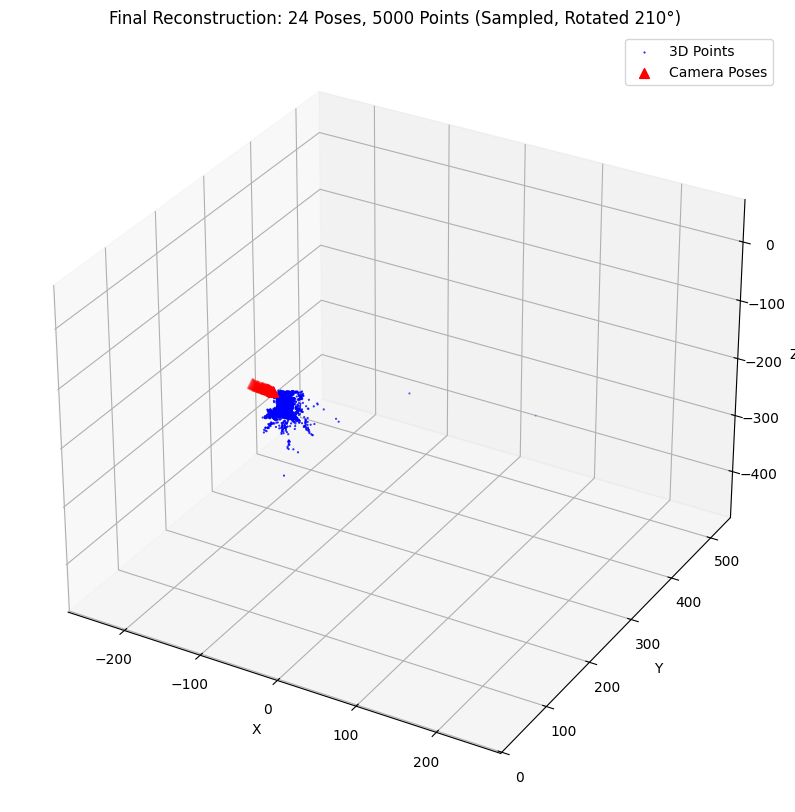

In [ ]:
print("\n--- Visualizing Final Reconstruction ---")
visualize_point_cloud(poses_world, points_3d_world, angle_deg=210, axis='x')

In [ ]:
# --- Run the pre-loading step ---
all_keypoints, all_image_sizes = load_all_keypoints(image_paths, FEATURES_DIR)

--- Loading all keypoints into memory ---


100%|██████████| 24/24 [00:00<00:00, 168.29it/s]


For all visualizations, scroll to the XY plane

In [ ]:
# Visualization before outlier removal
visualize_reconstruction_plotly(poses_world, points_3d_world, K, all_image_sizes)

Using image size 1920.0x1080.0 for frustum.


In the above plot there are a few outliers too far away in distance. So I wrote a method to remove outliers based on the euclidean distance between points.

In [ ]:
# Remove outliers based on distance
points_3d_world, point_id_to_kpt_idx = filter_far_points_by_distance(
                poses_world, points_3d_world, point_id_to_kpt_idx, percentile_threshold=98.0
              )


--- Filtering far distance outliers ---
Cloud centroid: [ 2.26 -0.85 37.67]
Distance threshold (98.0th percentile): 32.80 units
Removing 105 outlier points.
Removed 105 outlier 3D points from map.



--- Visualizing Final Reconstruction (Rotated 90 degrees around Z) ---
Applying 210-degree rotation around the X-axis.


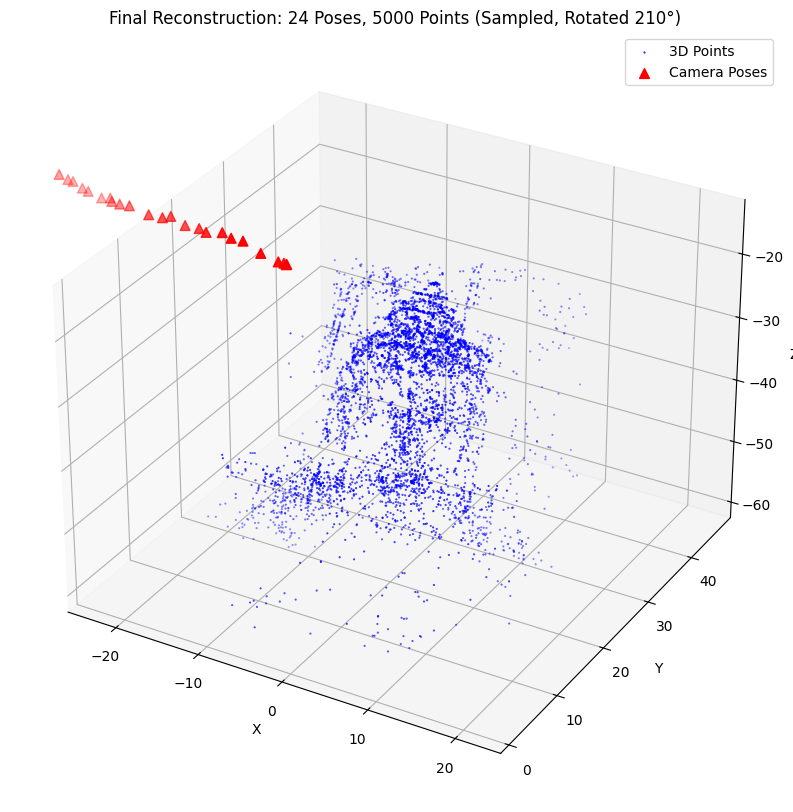

In [ ]:
print("\n--- Visualizing Final Reconstruction (Rotated 90 degrees around Z) ---")
visualize_point_cloud(poses_world, points_3d_world, angle_deg=210, axis='x')

In [ ]:
# Visualization after outlier removal
visualize_reconstruction_plotly(poses_world, points_3d_world, K, all_image_sizes)

Using image size 1920.0x1080.0 for frustum.


BUNDLE ADJUSTMENT

In [ ]:
# GTSAM Intrinsics
fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
K_gtsam = gtsam.Cal3_S2(fx, fy, 0, cx, cy)

# GTSAM Robust Noise Model
pixel_noise_base = gtsam.noiseModel.Isotropic.Sigma(2, 5.0)
robust_pixel_noise = gtsam.noiseModel.Robust(
    gtsam.noiseModel.mEstimator.Cauchy.Create(1.0),
    pixel_noise_base
)
print("GTSAM objects and Robust Noise Model initialized.")

GTSAM objects and Robust Noise Model initialized.


In [ ]:
# --- Run Global Bundle Adjustment ---
print("\n" + "="*50)
print("--- RUNNING GLOBAL BUNDLE ADJUSTMENT ---")
print("="*50 + "\n")

global_graph = gtsam.NonlinearFactorGraph()
global_values = gtsam.Values()

valid_poses = {}
valid_poses_indices = []
for idx, pose in poses_world.items():
    if pose is not None and not np.any(np.isnan(pose.matrix())):
        valid_poses[idx] = pose
        valid_poses_indices.append(idx)
    else:
        print(f"Warning: Skipping invalid (None or NaN) pose {idx}")

valid_points = {}
for p_id, p_3d in points_3d_world.items():
    if p_3d is not None and not np.any(np.isnan(p_3d)):
        valid_points[p_id] = p_3d
    else:
        print(f"Warning: Skipping invalid (None or NaN) point {p_id}")

if not valid_poses_indices:
    print("No valid poses found. Skipping Global BA.")
else:
    # Add all Pose Variables
    anchor_idx = seed_pair[0]

    if anchor_idx not in valid_poses_indices:
        print(f"Warning: Seed pose {anchor_idx} is not valid. "
              f"Anchoring to {min(valid_poses_indices)} instead.")
        anchor_idx = min(valid_poses_indices)

    print(f"Anchoring pose {anchor_idx} for Global BA.")
    anchor_key = gtsam.symbol('x', anchor_idx)

    # Insert all valid pose values first
    for img_idx, pose in valid_poses.items():
        global_values.insert(gtsam.symbol('x', img_idx), pose)

    # Add the anchor factor
    global_graph.add(gtsam.PriorFactorPose3(anchor_key,
                                            global_values.atPose3(anchor_key),
                                            gtsam.noiseModel.Constrained.All(6)))

    # Add all Point Variables and Projection Factors
    all_feats_global = {} # Load features for all valid poses
    for img_idx in valid_poses_indices:
        feats = torch.load(FEATURES_DIR / f'{image_paths[img_idx].stem}_feats.pt')
        all_feats_global[img_idx] = feats['keypoints'].cpu().numpy()

    for point_id, point_3d in valid_points.items():
        point_key = gtsam.symbol('l', point_id)
        global_values.insert(point_key, point_3d)

        for img_idx in valid_poses_indices:
            if img_idx in point_id_to_kpt_idx and point_id in point_id_to_kpt_idx[img_idx]:
                kpt_idx = point_id_to_kpt_idx[img_idx][point_id]
                uv = all_feats_global[img_idx][kpt_idx]
                pose_key = gtsam.symbol('x', img_idx)

                # Check for NaN keypoints
                if np.any(np.isnan(uv)):
                    print(f"Warning: Skipping NaN keypoint observation for p{point_id} in x{img_idx}")
                    continue

                factor = gtsam.GenericProjectionFactorCal3_S2(
                    uv, robust_pixel_noise, pose_key, point_key, K_gtsam
                )
                global_graph.add(factor)

    if global_graph.size() == 0:
        print("Global BA graph is empty. Skipping optimization.")
    else:
        # Optimize
        print("Starting Global BA optimization (this may take time)...")

        error_before_global_ba = calculate_total_reprojection_error(
            poses_world, valid_points, point_id_to_kpt_idx, image_paths, FEATURES_DIR, K)
        print(f"Mean Reprojection Error (BEFORE Global BA): {error_before_global_ba:.4f} pixels")

        global_params = gtsam.LevenbergMarquardtParams()
        global_optimizer = gtsam.LevenbergMarquardtOptimizer(global_graph, global_values, global_params)

        try:
            global_result = global_optimizer.optimize()
            print("Global BA optimization complete.")
        except Exception as e:
            print(f"ERROR: Global BA optimization failed: {e}")
            global_result = None

        # Update Map with Global Results
        if global_result is not None:
            print("Updating map with Global BA results...")

            # Create new dictionaries for the updated, optimized map
            optimized_poses_world = {}
            optimized_points_3d_world = {}

            for img_idx in valid_poses_indices:
                pose_key = gtsam.symbol('x', img_idx)
                if global_result.exists(pose_key):
                    optimized_poses_world[img_idx] = global_result.atPose3(pose_key)

            for point_id in valid_points.keys():
                point_key = gtsam.symbol('l', point_id)
                if global_result.exists(point_key):
                    optimized_points_3d_world[point_id] = global_result.atPoint3(point_key)

            # Filter outliers after optimization
            optimized_points_3d_world, point_id_to_kpt_idx = filter_far_points_by_distance(
                optimized_poses_world, optimized_points_3d_world, point_id_to_kpt_idx, percentile_threshold=98.0
            )

            # Calculate final error using the optimized and filtered maps
            error_after_global_ba = calculate_total_reprojection_error(
                optimized_poses_world, optimized_points_3d_world, point_id_to_kpt_idx, image_paths, FEATURES_DIR, K)
            print(f"Mean Reprojection Error (AFTER Global BA): {error_after_global_ba:.4f} pixels")

            # Overwrite the old maps with the new, optimized maps
            poses_world = optimized_poses_world
            points_3d_world = optimized_points_3d_world


--- RUNNING GLOBAL BUNDLE ADJUSTMENT ---

Anchoring pose 2 for Global BA.
Starting Global BA optimization (this may take time)...
Mean Reprojection Error (BEFORE Global BA): 2.1601 pixels
Global BA optimization complete.
Updating map with Global BA results...

--- Filtering far distance outliers ---
Cloud centroid: [ 2.04 -1.31 38.38]
Distance threshold (98.0th percentile): 20.60 units
Removing 103 outlier points.
Removed 103 outlier 3D points from map.
Mean Reprojection Error (AFTER Global BA): 221.9091 pixels


FINAL VISUALIZATION


--- Visualizing Final Reconstruction (Rotated 90 degrees around Z) ---
Applying 210-degree rotation around the X-axis.


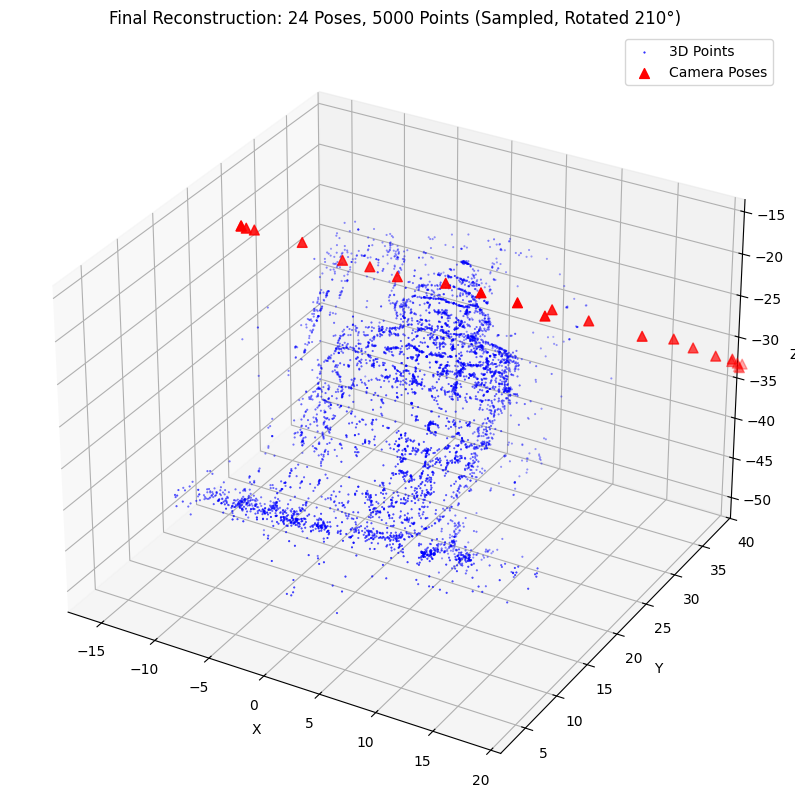

In [ ]:
print("\n--- Visualizing Final Reconstruction (Rotated 90 degrees around Z) ---")
visualize_point_cloud(poses_world, points_3d_world, angle_deg=210, axis='x')

In [ ]:
visualize_reconstruction_plotly(poses_world, points_3d_world, K, all_image_sizes)

Using image size 1920.0x1080.0 for frustum.


**Results and Discussion**

Key findings from this work include:

Adjusting the temporal window to include more pairwise matches yielded improved results. Optimal performance was achieved with a temporal_window = 6.

Using a deep learning model like SuperGlue for matching provides an advantage over traditional methods like SIFT, potentially due to the volume of keypoints generated. However, it requires high computational power for real-time inference.

A deeper understanding was gained of how OpenCV's Fundamental matrix (F), Essential matrix (E), and recoverPose methods work.

This project highlighted the importance of the camera intrinsics (K-matrix).

**Challenges:**

A few issues were encountered that remain unresolved:

The reprojection error increased significantly (or diverged) for unknown reasons after bundle adjustment, even though the qualitative results appeared better. The camera-to-world transformation is believed to be implemented correctly.

Determining the appropriate method for selecting a noise model for GTSAM was not resolved.